## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

In [2]:
import torch
print(torch.cuda.device_count())

1


In [3]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF2")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [4]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 1
GPU 0: Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [5]:
import os
import random
import json
import time
import math
import zipfile
import shutil
import numpy as np
import torch

# ---------------- Hugging Face dataset ----------------
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

# Verify these exact paths with the listing cell below before running
TRAIN_TEXT_FILES = [
    "Phase_2_LNER/Train/fold1-text.json",
    "Phase_2_LNER/Train/fold2-text.json",
]
TRAIN_GOLD_FILES = [
    "Phase_2_LNER/Train/fold1-gold.json",
    "Phase_2_LNER/Train/fold2-gold.json",
]
LABELS_FILE = "Phase_2_LNER/Train/labels.txt"
TEST_TEXT_FILE = "Phase_2_LNER/Test/fold3-text.json"

# ---------------- Phase 1 backbone (must match Phase 1 exactly) ----------------
# Path to the Phase 1 GQA checkpoint folder (contains model.safetensors + bpe_tokenizer.json)
PHASE1_CKPT_DIR = "/kaggle/input/datasets/himangshumahato/legal-grouped-query-lm"
MODEL_CONTEXT_LENGTH = 1024
N_EMBD = 768
N_LAYER = 12
N_HEAD = 12
N_KV_HEAD = 4

# ---------------- NER data / windowing ----------------
WINDOW_SIZE = 512        # tokens per window (must be <= MODEL_CONTEXT_LENGTH)
WINDOW_STRIDE = 256      # step between windows (overlap = WINDOW_SIZE - WINDOW_STRIDE)
# VAL_FRACTION = 0.10      # held-out share of training DOCUMENTS (split by document, not window)

# ---------------- LoRA ----------------
# LORA_R = 16
# LORA_ALPHA = 32
# LORA_DROPOUT = 0.05
# LORA_TARGETS = ["q_proj", "v_proj"]   # Config A; B adds k_proj, c_proj; C adds mlp.0, mlp.2

LR_BACKBONE = 3e-5     # all pretrained weights; try 3e-5 if training is unstable
LR_HEAD = 1e-3         # keep
LORA_R = 32
LORA_ALPHA = 64
LORA_DROPOUT = 0.05
LORA_TARGETS = ["q_proj", "k_proj", "v_proj", "c_proj", "mlp.0", "mlp.2"]   # Config C
# ---------------- Training ----------------
EPOCHS = 15
# EPOCHS = 10
BATCH_SIZE = 8
GRAD_ACCUM = 2
LR_LORA = 2e-4
LR_HEAD = 1e-3
WEIGHT_DECAY = 0.05
WARMUP_RATIO = 0.10
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---------------- Kaggle output ----------------
# EXPERIMENT_NAME = "gqa_lora_A" # change per experiment so outputs don't overwrite
EXPERIMENT_NAME = "gqa_full_ft"
OUTPUT_DIR = f"/kaggle/working/cs781_phase2/{EXPERIMENT_NAME}"
ADAPTER_PATH = os.path.join(OUTPUT_DIR, "full_model.pt")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Configuration loaded:", EXPERIMENT_NAME)

Configuration loaded: gqa_full_ft


In [6]:
!pip -q install peft regex
from huggingface_hub import hf_hub_download, HfApi

In [7]:
info = HfApi().dataset_info(HF_DATASET_REPO, files_metadata=True, token=HF_TOKEN)
for s in info.siblings:
    if "Phase_2" in s.rfilename:
        print(f"{s.rfilename:70s} {s.size/1e6:.2f} MB")

Phase_2_LNER/Test/fold3-text.json                                      1.19 MB
Phase_2_LNER/Train/fold1-gold.json                                     0.46 MB
Phase_2_LNER/Train/fold1-text.json                                     1.11 MB
Phase_2_LNER/Train/fold2-gold.json                                     0.48 MB
Phase_2_LNER/Train/fold2-text.json                                     1.12 MB
Phase_2_LNER/Train/labels.txt                                          0.00 MB


## 4. Load Tokenizer

In [8]:
%%writefile a1_tokenizer.py
"""From-scratch byte-level BPE tokenizer (GPT-2 style), no external tokenizer libs.

Differences from the plain-bytes version:
  * Text is first split into "words" with a GPT-2 style regex, and merges never
    cross word boundaries. Training and encoding then work on *unique words*
    (with counts) instead of the whole corpus, which is orders of magnitude faster.
  * Training uses incremental pair counts + a lazy max-heap (no full rescan per merge).
  * Encoding applies merges per word by rank, with a word -> ids cache.
  * One special token, <|endoftext|>, used as EOS / PAD / BOS.

Interface:
    tok.encode(text, add_eos=False) -> list[int]
    tok.decode(ids, skip_special_tokens=True) -> str
    tok.vocab_size / tok.get_vocab_size()
    tok.eos_token_id, tok.pad_token_id, tok.bos_token_id
    tok.save(path) / ByteLevelBPE.load(path)
"""

from __future__ import annotations

import heapq
import json
import time
from collections import Counter, defaultdict

import regex as re  # `pip install regex` (needed for \p{L} / \p{N})

# GPT-2 pre-tokenization pattern
_PAT = re.compile(
    r"""'s|'t|'re|'ve|'m|'ll|'d| ?\p{L}+| ?\p{N}+| ?[^\s\p{L}\p{N}]+|\s+(?!\S)|\s+"""
)

EOS_TOKEN = "<|endoftext|>"


class ByteLevelBPE:
    def __init__(self):
        # ids 0-255 = raw bytes; 256.. = learned merges; last id = <|endoftext|>
        self.merges: dict[tuple[int, int], int] = {}      # (a, b) -> new_id (id order == rank order)
        self.itos: dict[int, bytes] = {i: bytes([i]) for i in range(256)}
        self.eos_token_id = 256
        self.vocab_size = 257
        self._cache: dict[str, tuple] = {}

    # alias attributes so the tokenizer plugs into HF-style code
    @property
    def pad_token_id(self): return self.eos_token_id
    @property
    def bos_token_id(self): return self.eos_token_id

    def __len__(self): return self.vocab_size
    def get_vocab_size(self): return self.vocab_size

    def train(self, text: str, vocab_size: int, verbose: bool = False) -> None:
        """Learn (vocab_size - 257) merges; the final id is reserved for <|endoftext|>."""
        if vocab_size < 257:
            raise ValueError("vocab_size must be at least 257 (256 bytes + EOS)")
        num_merges = vocab_size - 257
        t0 = time.time()

        # 1) pre-tokenize and count unique words
        word_counts = Counter(_PAT.findall(text))
        words = [list(w.encode("utf-8")) for w in word_counts]
        freqs = list(word_counts.values())
        if verbose:
            print(f"[bpe] {len(words):,} unique words from {sum(freqs):,} total words")

        # 2) initial pair statistics
        stats: dict[tuple[int, int], int] = defaultdict(int)
        where: dict[tuple[int, int], set] = defaultdict(set)
        for wi, w in enumerate(words):
            f = freqs[wi]
            for p in zip(w, w[1:]):
                stats[p] += f
                where[p].add(wi)

        # lazy max-heap: (-count, a, b) -> highest count first, ties -> smallest (a, b)
        heap = [(-c, a, b) for (a, b), c in stats.items()]
        heapq.heapify(heap)

        self.merges, self.itos = {}, {i: bytes([i]) for i in range(256)}

        # 3) merge loop
        for i in range(num_merges):
            pair, count = None, 0
            while heap:
                negc, a, b = heapq.heappop(heap)
                if stats.get((a, b), 0) == -negc:   # skip stale heap entries
                    pair, count = (a, b), -negc
                    break
            if pair is None or count < 2:
                break

            new_id = 256 + i
            self.merges[pair] = new_id
            self.itos[new_id] = self.itos[pair[0]] + self.itos[pair[1]]

            touched = set()
            for wi in list(where[pair]):
                w, f = words[wi], freqs[wi]
                # remove this word's old pair contributions
                for p in zip(w, w[1:]):
                    stats[p] -= f
                    where[p].discard(wi)
                    touched.add(p)
                # apply merge (leftmost, non-overlapping)
                a, b = pair
                out, j, n = [], 0, len(w)
                while j < n:
                    if j < n - 1 and w[j] == a and w[j + 1] == b:
                        out.append(new_id); j += 2
                    else:
                        out.append(w[j]); j += 1
                words[wi] = out
                # add new pair contributions
                for p in zip(out, out[1:]):
                    stats[p] += f
                    where[p].add(wi)
                    touched.add(p)

            for p in touched:
                c = stats.get(p, 0)
                if c > 0:
                    heapq.heappush(heap, (-c, p[0], p[1]))
                else:
                    stats.pop(p, None)
                    where.pop(p, None)

            if verbose and (i % 1000 == 0 or i == num_merges - 1):
                print(f"[bpe] merge {i + 1}/{num_merges} | pair={pair} count={count:,} "
                      f"| elapsed={time.time() - t0:.1f}s")

        self.eos_token_id = 256 + len(self.merges)
        self.vocab_size = self.eos_token_id + 1
        self._cache = {}

    # Inference
    def _encode_word(self, word: str) -> tuple:
        hit = self._cache.get(word)
        if hit is not None:
            return hit
        ids = list(word.encode("utf-8"))
        merges = self.merges
        while len(ids) > 1:
            # pick the applicable merge learned earliest (lowest id)
            best, best_id = None, None
            for p in zip(ids, ids[1:]):
                nid = merges.get(p)
                if nid is not None and (best_id is None or nid < best_id):
                    best, best_id = p, nid
            if best is None:
                break
            a, b = best
            out, j, n = [], 0, len(ids)
            while j < n:
                if j < n - 1 and ids[j] == a and ids[j + 1] == b:
                    out.append(best_id); j += 2
                else:
                    out.append(ids[j]); j += 1
            ids = out
        res = tuple(ids)
        if len(self._cache) > 2_000_000:
            self._cache.clear()
        self._cache[word] = res
        return res

    def encode(self, text: str, add_eos: bool = False) -> list[int]:
        ids: list[int] = []
        for w in _PAT.findall(text):
            ids.extend(self._encode_word(w))
        if add_eos:
            ids.append(self.eos_token_id)
        return ids

    def decode(self, ids, skip_special_tokens: bool = True) -> str:
        if hasattr(ids, "tolist"):
            ids = ids.tolist()
        parts = []
        for i in ids:
            if i == self.eos_token_id:
                if not skip_special_tokens:
                    parts.append(EOS_TOKEN.encode("utf-8"))
                continue
            parts.append(self.itos[i])
        return b"".join(parts).decode("utf-8", errors="replace")

    def save(self, path: str) -> None:
        data = {
            "merges": [[a, b, nid] for (a, b), nid in self.merges.items()],
            "vocab_size": self.vocab_size,
            "eos_token_id": self.eos_token_id,
        }
        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f)

    @classmethod
    def load(cls, path: str) -> "ByteLevelBPE":
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        tok = cls()
        for a, b, nid in data["merges"]:
            tok.merges[(a, b)] = nid
            tok.itos[nid] = tok.itos[a] + tok.itos[b]
        tok.eos_token_id = data["eos_token_id"]
        tok.vocab_size = data["vocab_size"]
        return tok


def train_tokenizer(train_text: str, vocab_size: int):
    """Train a byte-level BPE tokenizer on `train_text` and return it."""
    tok = ByteLevelBPE()
    tok.train(train_text, vocab_size, verbose=True)
    return tok

Overwriting a1_tokenizer.py


In [9]:
from a1_tokenizer import ByteLevelBPE, _PAT

tokenizer = ByteLevelBPE.load(os.path.join(PHASE1_CKPT_DIR, "bpe_tokenizer.json"))
print("Vocabulary size:", len(tokenizer))

Vocabulary size: 32000


In [10]:
def encode_with_offsets(tok, text):
    """Returns ids, starts, ends, is_ws. Offsets are character offsets into `text`,
    end-exclusive, with leading/trailing whitespace trimmed from each token's span.
    is_ws[i] is True for tokens that are whitespace only (no usable span)."""
    ids, starts, ends, is_ws = [], [], [], []
    pos = 0
    for m in _PAT.finditer(text):
        assert m.start() == pos, "pre-tokenizer left a gap in the text"
        pos = m.end()
        word, c0 = m.group(), m.start()
        # byte index within the word -> character index in the text
        b2c = []
        for i, ch in enumerate(word):
            b2c.extend([c0 + i] * len(ch.encode("utf-8")))
        b = 0
        for tid in tok._encode_word(word):
            n = len(tok.itos[tid])
            s, e = b2c[b], b2c[b + n - 1] + 1
            b += n
            while s < e and text[s].isspace(): s += 1
            while e > s and text[e - 1].isspace(): e -= 1
            ids.append(tid); starts.append(s); ends.append(e); is_ws.append(s >= e)
    assert pos == len(text), "pre-tokenizer did not cover the whole text"
    return ids, starts, ends, is_ws

In [11]:
from huggingface_hub import hf_hub_download

def hf_json(path):
    p = hf_hub_download(repo_id=HF_DATASET_REPO, filename=path,
                        repo_type="dataset", token=HF_TOKEN)
    with open(p, encoding="utf-8") as f:
        return json.load(f)

train_text, train_gold, doc_fold = {}, {}, {}
for fold_i, (tf, gf) in enumerate(zip(TRAIN_TEXT_FILES, TRAIN_GOLD_FILES), start=1):
    t, g = hf_json(tf), hf_json(gf)
    train_text.update(t); train_gold.update(g)
    for d in t: doc_fold[d] = fold_i

test_text = hf_json(TEST_TEXT_FILE)

p = hf_hub_download(repo_id=HF_DATASET_REPO, filename=LABELS_FILE,
                    repo_type="dataset", token=HF_TOKEN)
LABELS = [l.strip() for l in open(p, encoding="utf-8") if l.strip()]

print("train docs:", len(train_text), "| gold docs:", len(train_gold), "| test docs:", len(test_text))
print({f: sum(1 for v in doc_fold.values() if v == f) for f in (1, 2)})

train docs: 70 | gold docs: 70 | test docs: 35
{1: 35, 2: 35}


In [12]:
# offsets must reproduce the same ids as the normal encoder
for d in list(train_text)[:5]:
    ids, s, e, w = encode_with_offsets(tokenizer, train_text[d])
    assert ids == tokenizer.encode(train_text[d]), d
print("ids match encode()")

n_tok = [len(encode_with_offsets(tokenizer, t)[0]) for t in train_text.values()]
print("tokens/doc min/mean/max:", min(n_tok), sum(n_tok)//len(n_tok), max(n_tok))

ids match encode()
tokens/doc min/mean/max: 2139 6618 23839


In [13]:
TAGS = ["O"] + [f"{p}-{l}" for l in LABELS for p in ("B", "I")]
TAG2ID = {t: i for i, t in enumerate(TAGS)}
ID2TAG = {i: t for t, i in TAG2ID.items()}
IGNORE = -100          
print(len(TAGS), "tags:", TAGS[:5], "...")

25 tags: ['O', 'B-APP', 'I-APP', 'B-RESP', 'I-RESP'] ...


In [14]:
def spans_to_bio(starts, ends, is_ws, gold_spans):
    """One tag id per token. gold_spans: [[start, end, label, (text)], ...]"""
    ents = sorted(gold_spans, key=lambda x: (x[0], x[1]))
    tags = []
    k = 0              # pointer into the sorted entities
    prev_ent = -1      # entity index of the previous non-whitespace token
    for i in range(len(starts)):
        if is_ws[i]:
            tags.append(IGNORE)          # whitespace never breaks an entity
            continue
        # skip entities that end at or before this token starts
        while k < len(ents) and ents[k][1] <= starts[i]:
            k += 1
        if k < len(ents) and ents[k][0] <= starts[i] < ents[k][1]:
            prefix = "I-" if prev_ent == k else "B-"
            tags.append(TAG2ID[prefix + ents[k][2]])
            prev_ent = k
        else:
            tags.append(TAG2ID["O"])
            prev_ent = -1
    return tags


def bio_to_spans(starts, ends, is_ws, tag_ids):
    """List of [start_char, end_char, label] from per-token tag ids."""
    spans, cur = [], None            # cur = [start, end, label]
    for i, t in enumerate(tag_ids):
        if is_ws[i] or t == IGNORE:
            continue
        tag = ID2TAG[int(t)]
        if tag == "O":
            if cur: spans.append(cur); cur = None
            continue
        prefix, label = tag.split("-", 1)
        if prefix == "I" and cur is not None and cur[2] == label:
            cur[1] = ends[i]                         # extend the open entity
        else:                                        # "B-" or a stray "I-"
            if cur: spans.append(cur)
            cur = [starts[i], ends[i], label]
    if cur: spans.append(cur)
    return spans

In [15]:
def span_set(spans):
    return {tuple(x[:3]) for x in spans}

tp = ngold = 0
fails = []
for d, ents in train_gold.items():
    text = train_text[d]
    ids, s, e, w = encode_with_offsets(tokenizer, text)
    tags = spans_to_bio(s, e, w, ents)
    back = bio_to_spans(s, e, w, tags)
    g, b = span_set(ents), span_set(back)
    tp += len(g & b); ngold += len(g)
    for x in ents:
        if tuple(x[:3]) not in b:
            fails.append((d, x[0], x[1], x[2], text[max(0, x[0]-10):x[1]+10]))

print(f"round-trip recovery: {tp}/{ngold} = {tp/ngold:.4f}")
for f in fails[:15]:
    print(f)

round-trip recovery: 8242/8393 = 0.9820
('115651329', 10266, 10299, 'PREC', 'e case of State of M.P. vs. Kashiram & Ors.[1], the s')
('975074', 7995, 8085, 'PREC', '1565] and Gambangi Appalaswamy Naldu and Others v. Behara Venkataramanayya Patro [AIR 1984- SC 1728]. Even oth')
('736324', 1963, 1976, 'AUTH', ' down the Railway Boards instruct')
('736324', 11218, 11231, 'AUTH', 'tation of Railway Boards decision')
('736324', 12849, 12901, 'PREC', ' cases in Shankarsan Dash Vs. Union of India [1991 (3) SCC 47]. Para 7 o')
('736324', 14121, 14174, 'PREC', 'C 268] or Jatendra Kumar vs. State of Punjab [(1985) 1 SCC 122]. Hence th')
('1243363', 17853, 17865, 'STAT', 'After the Constitutional Amendme')
('1243363', 25083, 25099, 'AUTH', 'uding the State Governments and the ')
('1243363', 25450, 25466, 'AUTH', 'ws of the State Governments and the ')
('373587', 5927, 5979, 'PREC', 'son. (See Hukam Singh v. State of Rajasthan AIR (1977 SC 1063); Eradu an')
('373587', 5981, 6035, 'PREC', 'SC 1063)

## Encode every document once (train and test)

In [16]:
enc = {}   # doc_id -> (ids, starts, ends, is_ws)
for d, t in {**train_text, **test_text}.items():
    enc[d] = encode_with_offsets(tokenizer, t)

tags_by_doc = {d: spans_to_bio(*enc[d][1:], train_gold[d]) for d in train_gold}
print("encoded docs:", len(enc), "| tagged docs:", len(tags_by_doc))

encoded docs: 105 | tagged docs: 70


## Windows

In [17]:
def window_starts(n_tokens, size, stride):
    """Token start positions of the windows covering a document of n_tokens."""
    if n_tokens <= size:
        return [0]
    starts = list(range(0, n_tokens - size + 1, stride))
    if starts[-1] + size < n_tokens:      # make sure the tail is covered
        starts.append(n_tokens - size)
    return starts

def build_windows(doc_ids, size=WINDOW_SIZE, stride=WINDOW_STRIDE, with_labels=True):
    items = []
    for d in doc_ids:
        ids = enc[d][0]
        for ws in window_starts(len(ids), size, stride):
            item = {"doc": d, "tok_start": ws, "input_ids": ids[ws:ws + size]}
            if with_labels:
                item["labels"] = tags_by_doc[d][ws:ws + size]
            items.append(item)
    return items

fold1_docs = [d for d, f in doc_fold.items() if f == 1]
fold2_docs = [d for d, f in doc_fold.items() if f == 2]

train_items = build_windows(fold1_docs)      # train on fold1
val_items   = build_windows(fold2_docs)      # validate on fold2
print("train windows:", len(train_items), "| val windows:", len(val_items))

# sanity: the windows must cover every token of every document
for d in fold1_docs[:5]:
    covered = set()
    for it in train_items:
        if it["doc"] == d:
            covered.update(range(it["tok_start"], it["tok_start"] + len(it["input_ids"])))
    assert covered == set(range(len(enc[d][0]))), d
print("window coverage OK")

train windows: 881 | val windows: 889
window coverage OK


## Collator

In [18]:
PAD_ID = tokenizer.eos_token_id

def ner_collator(batch):
    L = max(len(b["input_ids"]) for b in batch)
    ids = torch.full((len(batch), L), PAD_ID, dtype=torch.long)
    lab = torch.full((len(batch), L), IGNORE, dtype=torch.long)
    mask = torch.zeros((len(batch), L), dtype=torch.bool)
    for i, b in enumerate(batch):
        n = len(b["input_ids"])
        ids[i, :n] = torch.tensor(b["input_ids"])
        mask[i, :n] = True
        if "labels" in b:
            lab[i, :n] = torch.tensor(b["labels"])
    return {"input_ids": ids, "attention_mask": mask, "labels": lab}

b = ner_collator(train_items[:4])
print({k: v.shape for k, v in b.items()})

{'input_ids': torch.Size([4, 512]), 'attention_mask': torch.Size([4, 512]), 'labels': torch.Size([4, 512])}


In [19]:
import numpy as np
ent_frac = np.mean([any(l not in (0, IGNORE) for l in it["labels"]) for it in train_items])
print(f"windows containing at least one entity: {ent_frac:.2%}")

windows containing at least one entity: 95.91%


## 9. Define The Model

## Implementation for Grouped-Query Attention (GQA): 

In standard Multi-Head Attention (MHA), every query head has its own dedicated key and value head. In GQA, we divide the query heads into groups, and all queries within a single group share the same key and value heads. This drastically reduces the size of the KV-cache during inference (by a factor of the group size) while maintaining performance much closer to MHA than Multi-Query Attention (MQA) does.

In [20]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class GroupedQueryAttention(nn.Module):
    def __init__(self, n_embd, n_head, n_kv_head, n_positions, dropout=0.1):
        super().__init__()
        # Ensure dimensions cleanly divide
        assert n_embd % n_head == 0
        assert n_head % n_kv_head == 0
        
        self.n_head = n_head
        self.n_kv_head = n_kv_head
        self.head_dim = n_embd // n_head
        self.num_groups = n_head // n_kv_head  # Number of Q heads that share 1 KV head
        
        # Independent projections for Q, K, V to clearly handle differing head counts
        self.q_proj = nn.Linear(n_embd, n_embd)
        self.k_proj = nn.Linear(n_embd, n_kv_head * self.head_dim)
        self.v_proj = nn.Linear(n_embd, n_kv_head * self.head_dim)
        
        self.c_proj = nn.Linear(n_embd, n_embd)
        
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        
        self.register_buffer(
            "bias", 
            torch.tril(torch.ones(n_positions, n_positions)).view(1, 1, n_positions, n_positions)
        )

    def forward(self, x, layer_past=None):
        B, T, C = x.size()
        
        # 1. Project Q, K, V
        q = self.q_proj(x).view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv_head, self.head_dim).transpose(1, 2)
        
        # 2. KV-Caching Logic
        if layer_past is not None:
            past_k, past_v = layer_past
            k = torch.cat([past_k, k], dim=-2)
            v = torch.cat([past_v, v], dim=-2)
        
        present = (k, v)
        past_length = layer_past[0].size(-2) if layer_past is not None else 0
        seq_len = T + past_length
        
        # 3. GQA Broadcast: Repeat K and V to match the number of Q heads
        k = k.repeat_interleave(self.num_groups, dim=1)
        v = v.repeat_interleave(self.num_groups, dim=1)
        
        # 4. Attention Score Computation (Q @ K^T)
        att = q @ k.transpose(-2, -1)
        
        # 5. Score Scaling (1 / sqrt(d_k)) BEFORE Softmax
        att = att * (1.0 / math.sqrt(self.head_dim))
        
        # 6. Causal Masking
        mask = self.bias[:, :, past_length:past_length+T, :seq_len] == 0
        att = att.masked_fill(mask, float('-inf'))
        
        # 7. Softmax and Dropout
        att = F.softmax(att, dim=-1)
        att = self.attn_dropout(att)
        
        # 8. Multiply by V and project
        y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        
        return self.resid_dropout(self.c_proj(y)), present


class GQATransformerBlock(nn.Module):
    def __init__(self, n_embd, n_head, n_kv_head, n_positions, dropout=0.1):
        super().__init__()
        self.ln_1 = nn.LayerNorm(n_embd)
        self.attn = GroupedQueryAttention(n_embd, n_head, n_kv_head, n_positions, dropout)
        self.ln_2 = nn.LayerNorm(n_embd)
        
        self.mlp = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(approximate='tanh'),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout)
        )

    def forward(self, x, layer_past=None):
        # RESIDUAL CONNECTION 1: Add attention output to the original input
        attn_out, present = self.attn(self.ln_1(x), layer_past=layer_past)
        x = x + attn_out
        
        # RESIDUAL CONNECTION 2: Add MLP output to the normalized attention output
        x = x + self.mlp(self.ln_2(x))
        
        return x, present


class ScratchGroupedQueryLM(nn.Module):
    def __init__(self, vocab_size, n_positions, n_embd, n_layer, n_head, n_kv_head, dropout=0.1):
        super().__init__()
        self.wte = nn.Embedding(vocab_size, n_embd)
        self.wpe = nn.Embedding(n_positions, n_embd)
        self.drop = nn.Dropout(dropout)

        self.h = nn.ModuleList([
            GQATransformerBlock(n_embd, n_head, n_kv_head, n_positions, dropout)
            for _ in range(n_layer)
        ])

        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size, bias=False)

        self.apply(self._init_weights)
        for name, p in self.named_parameters():
            if name.endswith("c_proj.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_layer))

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, labels=None, past_key_values=None, attention_mask=None, **kwargs):
        B, T = input_ids.size()

        past_length = past_key_values[0][0].size(-2) if past_key_values is not None else 0
        pos = torch.arange(past_length, past_length + T, dtype=torch.long, device=input_ids.device)

        x = self.wte(input_ids) + self.wpe(pos)
        x = self.drop(x)

        presents = []
        for i, block in enumerate(self.h):
            layer_past = past_key_values[i] if past_key_values is not None else None
            x, present = block(x, layer_past=layer_past)
            presents.append(present)

        x = self.ln_f(x)
        logits = self.lm_head(x)

        loss = None
        if labels is not None:
            shift_logits = logits[..., :-1, :].contiguous()
            shift_labels = labels[..., 1:].contiguous()
            loss = F.cross_entropy(shift_logits.view(-1, shift_logits.size(-1)), shift_labels.view(-1))

        return {"loss": loss, "logits": logits, "past_key_values": tuple(presents)}
        

## Load the Phase 1 backbone

In [21]:
!pip -q install -U torchao

In [22]:
from safetensors.torch import load_file

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

lm = ScratchGroupedQueryLM(
    vocab_size=tokenizer.vocab_size,
    n_positions=MODEL_CONTEXT_LENGTH,
    n_embd=N_EMBD, n_layer=N_LAYER, n_head=N_HEAD, n_kv_head=N_KV_HEAD,
)
state = load_file(os.path.join(PHASE1_CKPT_DIR, "model.safetensors"))
print(lm.load_state_dict(state))     # should say <All keys matched successfully>
print(f"backbone: {sum(p.numel() for p in lm.parameters())/1e6:.2f}M params")

<All keys matched successfully>
backbone: 125.54M params


## The NER model

In [23]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class NERModel(nn.Module):
    def __init__(self, lm, n_tags, dropout=0.1, class_weights=None):
        super().__init__()
        self.lm = lm
        del self.lm.lm_head                      # NER doesn't predict next tokens
        self.dropout = nn.Dropout(dropout)
        
        # N_EMBD should be accessible here, or passed as an argument if it throws an error
        self.head = nn.Linear(N_EMBD, n_tags)    # 768 -> 25 BIO tags
        
        # Register class weights as a buffer so it automatically moves to the correct device
        if class_weights is not None:
            self.register_buffer('class_weights', torch.tensor(class_weights, dtype=torch.float))
        else:
            self.class_weights = None

    def forward(self, input_ids, labels=None, attention_mask=None):
        B, T = input_ids.shape
        positions = torch.arange(T, device=input_ids.device)
        x = self.lm.wte(input_ids) + self.lm.wpe(positions)
        x = self.lm.drop(x)
        for block in self.lm.h:
            x, _ = block(x)
        x = self.lm.ln_f(x)
        logits = self.head(self.dropout(x))      # [B, T, n_tags]

        loss = None
        if labels is not None:
            # Apply weights if they were provided during initialization
            if self.class_weights is not None:
                loss = F.cross_entropy(
                    logits.view(-1, logits.size(-1)), labels.view(-1),
                    ignore_index=IGNORE,
                    weight=self.class_weights
                )
            else:
                loss = F.cross_entropy(
                    logits.view(-1, logits.size(-1)), labels.view(-1),
                    ignore_index=IGNORE
                )
                
        return {"loss": loss, "logits": logits}

## Full fine-tuning

In [24]:
import numpy as np

# Calculate class weights based on training data frequencies
tag_counts = {i: 0 for i in range(len(TAGS))}
total_valid_tokens = 0

for item in train_items:
    for label in item["labels"]:
        if label != IGNORE:
            tag_counts[label] += 1
            total_valid_tokens += 1

class_weights = []
for i in range(len(TAGS)):
    count = tag_counts[i]
    if count > 0:
        weight = total_valid_tokens / (len(TAGS) * count)
    else:
        weight = 0.0
    class_weights.append(weight)

# Clip weights to prevent extreme gradients
class_weights = np.clip(class_weights, a_min=0.1, a_max=10.0).tolist()
print("Class weights calculated.")

Class weights calculated.


In [25]:
# Pass the class_weights we just calculated
ner_model = NERModel(lm, n_tags=len(TAGS), dropout=0.25, class_weights=class_weights)

# FULL fine-tuning: every parameter trains (nothing frozen, no adapters)
for p in ner_model.parameters():
    p.requires_grad = True

ner_model.to(device)
trainable = sum(p.numel() for p in ner_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in ner_model.parameters())
print(f"trainable {trainable:,} / {total:,} ({100*trainable/total:.2f}%)")

trainable 100,988,185 / 100,988,185 (100.00%)


## 10. Optimizer and Schedule

In [26]:
from torch.utils.data import DataLoader
from torch.optim import AdamW

backbone_params = [p for n, p in ner_model.named_parameters() if not n.startswith("head.")]
head_params     = [p for n, p in ner_model.named_parameters() if n.startswith("head.")]
optimizer = AdamW([
    {"params": backbone_params, "lr": LR_BACKBONE},
    {"params": head_params,     "lr": LR_HEAD},
], weight_decay=WEIGHT_DECAY)

train_loader = DataLoader(train_items, batch_size=BATCH_SIZE, shuffle=True, collate_fn=ner_collator)
val_loader   = DataLoader(val_items,   batch_size=BATCH_SIZE, shuffle=False, collate_fn=ner_collator)

steps_per_epoch = math.ceil(len(train_loader) / GRAD_ACCUM)
total_steps = steps_per_epoch * EPOCHS
warmup_steps = int(WARMUP_RATIO * total_steps)

def lr_factor(step):                      # linear warm-up, then linear decay to 0
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    return max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
print("optimizer steps:", total_steps, "| warmup:", warmup_steps)

@torch.no_grad()
def eval_loss(model, loader):
    model.eval()
    tot, n = 0.0, 0
    for b in loader:
        b = {k: v.to(device) for k, v in b.items()}
        out = model(**b)
        k = (b["labels"] != IGNORE).sum().item()      # count of real label positions
        tot += out["loss"].item() * k; n += k
    return tot / n

optimizer steps: 840 | warmup: 84


## Predict a document and merge overlapping windows

In [27]:
@torch.no_grad()
def predict_doc_logprobs(model, doc_id, size=WINDOW_SIZE, stride=WINDOW_STRIDE, bs=16):
    """Average log-probabilities over all windows that cover each token."""
    model.eval()
    ids = enc[doc_id][0]
    n = len(ids)
    starts = window_starts(n, size, stride)
    acc = torch.zeros(n, len(TAGS))
    cnt = torch.zeros(n)
    for i in range(0, len(starts), bs):
        chunk = starts[i:i + bs]
        batch = ner_collator([{"input_ids": ids[w:w + size]} for w in chunk])
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(input_ids=batch["input_ids"].to(device))["logits"]
        lp = logits.float().log_softmax(-1).cpu()
        for j, w in enumerate(chunk):
            L = min(size, n - w)
            acc[w:w + L] += lp[j, :L]
            cnt[w:w + L] += 1
    return acc / cnt[:, None]

def predict_spans(model, doc_id):
    avg = predict_doc_logprobs(model, doc_id)
    tag_ids = avg.argmax(-1).tolist()
    _, s, e, w = enc[doc_id]
    return bio_to_spans(s, e, w, tag_ids)


## Strict scorer

In [28]:
def strict_scores(gold_by_doc, pred_by_doc, verbose=True):
    cnts = {l: [0, 0, 0] for l in LABELS}          # tp, n_pred, n_gold
    for d, gold in gold_by_doc.items():
        g = {tuple(x[:3]) for x in gold}
        p = {tuple(x[:3]) for x in pred_by_doc.get(d, [])}
        for l in LABELS:
            gl = {x for x in g if x[2] == l}
            pl = {x for x in p if x[2] == l}
            cnts[l][0] += len(gl & pl); cnts[l][1] += len(pl); cnts[l][2] += len(gl)
    rows, Ps, Rs, Fs = [], [], [], []
    for l in LABELS:
        tp, npred, ngold = cnts[l]
        P = tp / npred if npred else 0.0
        R = tp / ngold if ngold else 0.0
        F = 2 * P * R / (P + R) if P + R else 0.0
        Ps.append(P); Rs.append(R); Fs.append(F)
        rows.append((l, P, R, F, ngold))
    if verbose:
        print(f"{'label':10s} {'P':>6s} {'R':>6s} {'F1':>6s} {'#gold':>6s}")
        for l, P, R, F, n in rows:
            print(f"{l:10s} {P:6.3f} {R:6.3f} {F:6.3f} {n:6d}")
    macro = (sum(Ps) / len(Ps), sum(Rs) / len(Rs), sum(Fs) / len(Fs))
    print(f"MACRO  P {macro[0]:.4f}  R {macro[1]:.4f}  F1 {macro[2]:.4f}")
    return macro

## 11. Training

In [29]:
PATIENCE = 5                 # stop after this many epochs without F1 improvement
USE_AMP = torch.cuda.is_available()
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
history = {"train": [], "val": [], "f1": []}
best_f1, bad_epochs = 0.0, 0

def trainable_state(model):
    return {n: p.detach().cpu() for n, p in model.named_parameters() if p.requires_grad}

val_gold = {d: train_gold[d] for d in fold2_docs}
t0 = time.time()
for epoch in range(EPOCHS):
    ner_model.train()
    run, cnt = 0.0, 0
    optimizer.zero_grad()
    for i, b in enumerate(train_loader):
        b = {k: v.to(device) for k, v in b.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            loss = ner_model(**b)["loss"]
        scaler.scale(loss / GRAD_ACCUM).backward()
        run += loss.item(); cnt += 1
        if (i + 1) % GRAD_ACCUM == 0 or (i + 1) == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(ner_model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update()
            optimizer.zero_grad(); scheduler.step()

    v = eval_loss(ner_model, val_loader)
    val_pred = {d: predict_spans(ner_model, d) for d in fold2_docs}
    f1 = strict_scores(val_gold, val_pred, verbose=False)[2]
    history["train"].append(run / cnt); history["val"].append(v); history["f1"].append(f1)
    print(f"epoch {epoch+1}/{EPOCHS} | train {run/cnt:.4f} | val loss {v:.4f} | val F1 {f1:.4f} | {time.time()-t0:.0f}s")

    if f1 > best_f1:
        best_f1, bad_epochs = f1, 0
        torch.save(trainable_state(ner_model), ADAPTER_PATH)
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f"early stopping at epoch {epoch+1} (best F1 {best_f1:.4f})")
            break

# restore the best epoch before any further evaluation or prediction
ner_model.load_state_dict(torch.load(ADAPTER_PATH), strict=False)
print("restored best checkpoint, val F1:", best_f1)

MACRO  P 0.0643  R 0.2384  F1 0.0997
epoch 1/15 | train 2.3167 | val loss 0.9492 | val F1 0.0997 | 65s
MACRO  P 0.1250  R 0.3414  F1 0.1790
epoch 2/15 | train 0.4284 | val loss 0.6648 | val F1 0.1790 | 135s
MACRO  P 0.1492  R 0.3632  F1 0.2074
epoch 3/15 | train 0.1774 | val loss 0.7097 | val F1 0.2074 | 206s
MACRO  P 0.1953  R 0.3955  F1 0.2554
epoch 4/15 | train 0.0940 | val loss 0.8577 | val F1 0.2554 | 278s
MACRO  P 0.2088  R 0.4116  F1 0.2712
epoch 5/15 | train 0.0619 | val loss 0.9182 | val F1 0.2712 | 350s
MACRO  P 0.2274  R 0.4187  F1 0.2886
epoch 6/15 | train 0.0457 | val loss 1.0241 | val F1 0.2886 | 422s
MACRO  P 0.2459  R 0.4189  F1 0.3039
epoch 7/15 | train 0.0383 | val loss 1.1430 | val F1 0.3039 | 494s
MACRO  P 0.2522  R 0.4388  F1 0.3148
epoch 8/15 | train 0.0304 | val loss 1.0912 | val F1 0.3148 | 566s
MACRO  P 0.2491  R 0.4348  F1 0.3121
epoch 9/15 | train 0.0263 | val loss 1.1023 | val F1 0.3121 | 638s
MACRO  P 0.2581  R 0.4304  F1 0.3174
epoch 10/15 | train 0.0228 |

In [30]:
print("ADAPTER_PATH:", ADAPTER_PATH)
print("method: full fine-tuning | lr backbone/head:", LR_BACKBONE, LR_HEAD)
print("trainable:", sum(p.numel() for p in ner_model.parameters() if p.requires_grad))
print("history:", history)
res = ner_model.load_state_dict(torch.load(ADAPTER_PATH), strict=False)
print("unexpected keys:", res.unexpected_keys[:5], len(res.unexpected_keys))
print("missing keys:", len(res.missing_keys), res.missing_keys[:3])

ADAPTER_PATH: /kaggle/working/cs781_phase2/gqa_full_ft/full_model.pt
method: full fine-tuning | lr backbone/head: 3e-05 0.001
trainable: 100988185
history: {'train': [2.3167224816373877, 0.42838196617525975, 0.17739612665362992, 0.09400374643705986, 0.06188221341670231, 0.045717369999971474, 0.03827114969592642, 0.030432481251589885, 0.026328384549029776, 0.022789303406334675, 0.021028891147055605, 0.018981528873261704, 0.017620278430079017, 0.01693640538986336, 0.01668661146063928], 'val': [0.9491888966110597, 0.6647519405451061, 0.709709722777318, 0.857740192735309, 0.9181882886939317, 1.024111248480508, 1.1429708734216515, 1.09122752066826, 1.1022504091360252, 1.2080233544001244, 1.2201269845775373, 1.244764725874882, 1.2682551086256444, 1.2889886487783038, 1.2941565219652689], 'f1': [0.09971587226267936, 0.17899778487383047, 0.2073595377466848, 0.2553693421095183, 0.2712136026960953, 0.28864079333990056, 0.3038942313940712, 0.31480501005100053, 0.31209053842113516, 0.31742972499756

## Evaluate the best checkpoint on fold2

In [31]:
# load the best epoch (the in-memory model is epoch 5)
print(ner_model.load_state_dict(torch.load(ADAPTER_PATH), strict=False).unexpected_keys)

val_pred = {d: predict_spans(ner_model, d) for d in fold2_docs}
val_gold = {d: train_gold[d] for d in fold2_docs}
strict_scores(val_gold, val_pred)

[]
label           P      R     F1  #gold
APP         0.055  0.110  0.073    200
RESP        0.058  0.100  0.073    190
A.COUNSEL   0.199  0.272  0.230    125
R.COUNSEL   0.241  0.546  0.334     97
JUDGE       0.262  0.582  0.361    122
WIT         0.144  0.142  0.143    120
AUTH        0.229  0.348  0.277    468
COURT       0.620  0.841  0.713    558
STAT        0.396  0.614  0.481    735
PREC        0.184  0.367  0.245    559
DATE        0.753  0.924  0.830    762
CASENO      0.168  0.433  0.242    337
MACRO  P 0.2757  R 0.4399  F1 0.3335


(0.2756537087864012, 0.43985572480837004, 0.3335428960822437)

In [32]:
train_pred = {d: predict_spans(ner_model, d) for d in fold1_docs}
train_gold1 = {d: train_gold[d] for d in fold1_docs}
strict_scores(train_gold1, train_pred)

label           P      R     F1  #gold
APP         0.585  0.845  0.692    207
RESP        0.609  0.895  0.725    191
A.COUNSEL   0.739  0.971  0.840     70
R.COUNSEL   0.757  1.000  0.861     87
JUDGE       0.392  0.650  0.489    123
WIT         0.561  0.955  0.707     67
AUTH        0.591  0.933  0.724    535
COURT       0.724  0.905  0.805    455
STAT        0.663  0.907  0.766    525
PREC        0.381  0.583  0.461    624
DATE        0.870  0.980  0.922    813
CASENO      0.543  0.915  0.681    423
MACRO  P 0.6179  R 0.8784  F1 0.7227


(0.6179097855771013, 0.8784313123593983, 0.7226628470412341)

## 13. Plot Training and Validation Loss

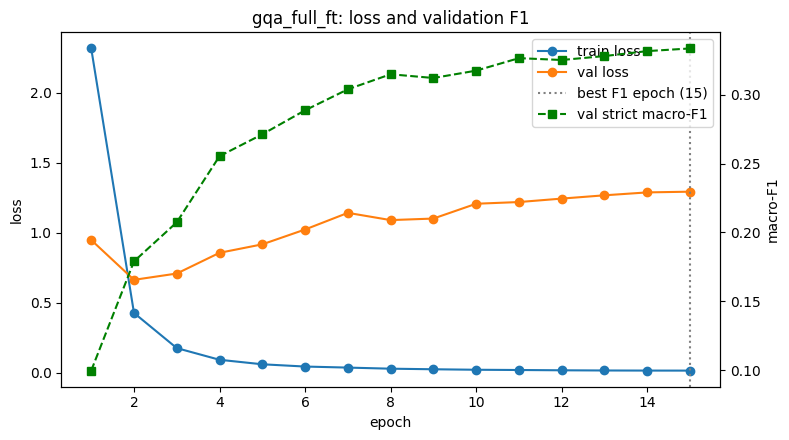

In [33]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train"]) + 1)
fig, ax1 = plt.subplots(figsize=(8, 4.5))

ax1.plot(epochs, history["train"], marker="o", label="train loss")
ax1.plot(epochs, history["val"], marker="o", label="val loss")
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss")

ax2 = ax1.twinx()
ax2.plot(epochs, history["f1"], marker="s", color="green", linestyle="--", label="val strict macro-F1")
ax2.set_ylabel("macro-F1")

best = max(range(len(history["f1"])), key=lambda i: history["f1"][i]) + 1
ax1.axvline(best, color="gray", linestyle=":", label=f"best F1 epoch ({best})")

h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right")
plt.title(f"{EXPERIMENT_NAME}: loss and validation F1")
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=150)
plt.show()

## 14. Save Final Model to Kaggle Output

In [34]:
size_mb = os.path.getsize(ADAPTER_PATH) / (1024 ** 2)
print(f"saved checkpoint (all parameters): {size_mb:.0f} MB")

run_info = {
    "experiment": EXPERIMENT_NAME,
    "method": "full_finetune",
    "phase1_model": "GQA (Model 3)",
    "lr_backbone": LR_BACKBONE, "lr_head": LR_HEAD,
    "weight_decay": WEIGHT_DECAY, "batch_size": BATCH_SIZE, "grad_accum": GRAD_ACCUM,
    "window": WINDOW_SIZE, "stride": WINDOW_STRIDE,
    "epochs_planned": EPOCHS, "epochs_run": len(history["f1"]),
    "best_epoch": history["f1"].index(max(history["f1"])) + 1,
    "best_val_f1": max(history["f1"]),
    "trainable_params": sum(p.numel() for p in ner_model.parameters() if p.requires_grad),
    "total_params": sum(p.numel() for p in ner_model.parameters()),
    "checkpoint_mb": round(size_mb, 1),
    "train_seconds": round(time.time() - t0),
}
with open(os.path.join(OUTPUT_DIR, "run_info.json"), "w") as f:
    json.dump(run_info, f, indent=2)
print(run_info)

saved checkpoint (all parameters): 385 MB
{'experiment': 'gqa_full_ft', 'method': 'full_finetune', 'phase1_model': 'GQA (Model 3)', 'lr_backbone': 3e-05, 'lr_head': 0.001, 'weight_decay': 0.05, 'batch_size': 8, 'grad_accum': 2, 'window': 512, 'stride': 256, 'epochs_planned': 15, 'epochs_run': 15, 'best_epoch': 15, 'best_val_f1': 0.3335428960822437, 'trainable_params': 100988185, 'total_params': 100988185, 'checkpoint_mb': 385.3, 'train_seconds': 1089}


## For reload purpose

In [35]:
# # rebuild exactly as in training, then load the full fine-tuned weights
# lm = ScratchGroupedQueryLM(vocab_size=tokenizer.vocab_size, n_positions=MODEL_CONTEXT_LENGTH,
#                            n_embd=N_EMBD, n_layer=N_LAYER, n_head=N_HEAD, n_kv_head=N_KV_HEAD)
# ner_model = NERModel(lm, n_tags=len(TAGS)).to(device)
# res = ner_model.load_state_dict(torch.load(ADAPTER_PATH, map_location=device), strict=False)
# print(res.unexpected_keys, len(res.missing_keys))

## Predict fold3

In [36]:
test_pred = {}
for d in test_text:                       # fold3 documents, all required IDs
    test_pred[d] = [[int(s), int(e), lab] for s, e, lab in predict_spans(ner_model, d)]

assert set(test_pred) == set(test_text), "missing or extra document ids"
print("docs:", len(test_pred), "| total spans:", sum(len(v) for v in test_pred.values()))

# sanity: spans are inside the text, non-empty, labels valid
for d, spans in test_pred.items():
    n = len(test_text[d])
    for s, e, lab in spans:
        assert 0 <= s < e <= n and lab in LABELS, (d, s, e, lab)
print("format checks OK")
d0 = next(iter(test_pred))
print([(s, e, lab, test_text[d0][s:e]) for s, e, lab in test_pred[d0][:5]])

docs: 35 | total spans: 6808
format checks OK
[(18, 46, 'COURT', 'SUPREME COURT OF INDIA CIVIL'), (70, 98, 'CASENO', 'CIVIL APPEAL NO.6580 OF 2008'), (99, 106, 'APP', 'ARISING'), (107, 162, 'CASENO', 'OUT OF SPECIAL LEAVE PETITION (CIVIL) NO. 15449 OF 2004'), (163, 168, 'APP', 'ESSCO')]


## 21. Save prediction.json and Create CodaBench Submission ZIP

In [37]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(test_pred, f, ensure_ascii=False)

with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as z:
    z.write(PREDICTION_PATH, arcname="prediction.json")     # must sit at the zip root

print("saved:", SUBMISSION_ZIP)
with zipfile.ZipFile(SUBMISSION_ZIP) as z:
    print(z.namelist())                                    # expect ['prediction.json']

saved: /kaggle/working/cs781_phase2/gqa_full_ft/submission.zip
['prediction.json']


In [39]:
import shutil
shutil.make_archive("/kaggle/working/phase2_backup", "zip", "/kaggle/working/cs781_phase2")
shutil.copy("/kaggle/working/a1_tokenizer.py", "/kaggle/working/cs781_phase2/a1_tokenizer.py")
print(os.path.getsize("/kaggle/working/phase2_backup.zip") / 1e6, "MB")

375.478407 MB
